# Del ciclo de manchas solares a la actividad geomagnética
### Modelización y pronóstico del índice Ap mediante observaciones solares — TP Final, Series Temporales (UCA, 2026)
**Juan Cruz Montero**

Este notebook reproduce **todo** el análisis del informe sobre tres series de clima espacial:
el número de manchas solares (SN, SILSO), el índice geomagnético planetario **Ap** y el flujo solar
F10.7 (GFZ Potsdam). Aplica el pipeline completo del curso: exploratorio y descomposición,
estacionariedad (ADF/KPSS), correlograma y ruido blanco, ARMA/ARIMA, SARIMA, causalidad de Granger +
VAR/IRF, y modelos ARCH/GARCH, cerrando con un backtest integrador nivel vs. volatilidad.

Los datos se leen de la carpeta `data/` (los mismos archivos SILSO y GFZ que acompañan al paquete).

In [1]:
# Dependencias (descomentar si hace falta):
# !pip install statsmodels arch --quiet
%matplotlib inline
import numpy as np, pandas as pd, warnings
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf, grangercausalitytests
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.api import VAR
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from arch import arch_model
import scipy.stats as st
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi":110,"font.size":9,"axes.grid":True,"grid.alpha":.3})
DATA = ""   # los archivos SN_...csv y Kp_...txt van en la MISMA carpeta que este notebook
print("Entorno listo.")

Entorno listo.


## 1. Carga de datos y panel mensual

In [2]:
# --- SILSO: número de manchas mensual (1749-2026) ---
sn = pd.read_csv(DATA+"SN_m_tot_V2_0.csv", sep=";", header=None,
                 names=["y","m","dec","sn","sd","nobs","prov"])
sn["date"] = pd.to_datetime(dict(year=sn.y, month=sn.m, day=1))
SN = sn.set_index("date")["sn"].asfreq("MS")

# --- GFZ: Ap, SN y F10.7 diarios (1932-2026) ---
cols = ["y","m","d","days","days_m","bsr","dB"]+[f"Kp{i}" for i in range(1,9)]+\
       [f"ap{i}" for i in range(1,9)]+["Ap","SN","F107obs","F107adj","D"]
g = pd.read_csv(DATA+"Kp_ap_Ap_SN_F107_since_1932.txt", sep=r"\s+", comment="#",
                header=None, names=cols)
g["date"] = pd.to_datetime(dict(year=g.y, month=g.m, day=g.d))
g = g.set_index("date")
Ap_d  = g["Ap"].replace(-1, np.nan).asfreq("D")           # Ap diario
F107  = g["F107obs"].replace(-1.0, np.nan)

# --- panel mensual conjunto (desde 1947, inicio de F10.7) ---
M = pd.DataFrame({"Ap":  g["Ap"].replace(-1,np.nan).resample("MS").mean(),
                  "SN":  SN,
                  "F107": F107.resample("MS").mean()}).dropna()
print(f"SN mensual : {SN.notna().sum():5d} obs  {SN.index.min().date()} -> {SN.index.max().date()}")
print(f"Ap diario  : {Ap_d.notna().sum():5d} obs  {Ap_d.index.min().date()} -> {Ap_d.index.max().date()}")
print(f"Panel mens.: {len(M):5d} obs  {M.index.min().date()} -> {M.index.max().date()}")

SN mensual :  3330 obs  1749-01-01 -> 2026-06-01
Ap diario  : 34527 obs  1932-01-01 -> 2026-07-12
Panel mens.:   953 obs  1947-02-01 -> 2026-06-01


## 2. Análisis exploratorio

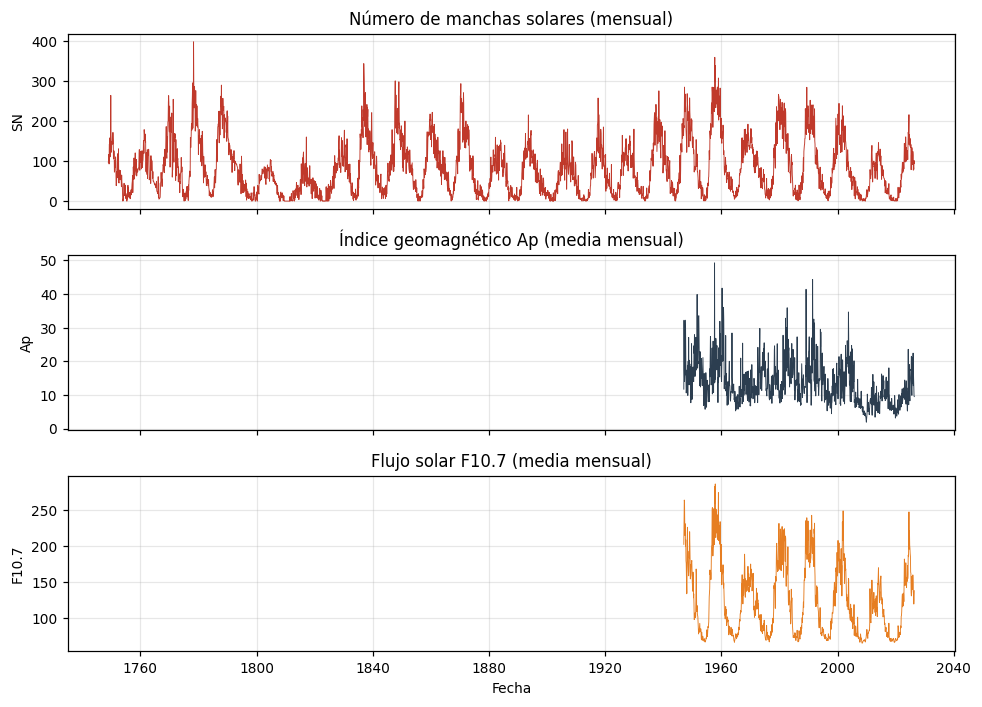

                  n  media    sd   min    max  skew   kurt
SN           3330.0   82.2  67.6   0.0  398.2  0.91   0.32
Ap_mensual    953.0   13.4   6.4   1.9   49.3  1.28   2.71
Ap_diario   34527.0   13.3  15.3   0.0  280.0  4.71  38.60
F107          953.0  125.0  50.0  65.7  286.5  0.75  -0.39


In [3]:
fig, ax = plt.subplots(3,1, figsize=(9,6.5), sharex=True)
ax[0].plot(SN.index, SN.values, lw=.6, color="#c0392b"); ax[0].set_ylabel("SN")
ax[0].set_title("Número de manchas solares (mensual)")
ax[1].plot(M.index, M["Ap"], lw=.6, color="#2c3e50"); ax[1].set_ylabel("Ap")
ax[1].set_title("Índice geomagnético Ap (media mensual)")
ax[2].plot(M.index, M["F107"], lw=.6, color="#e67e22"); ax[2].set_ylabel("F10.7")
ax[2].set_title("Flujo solar F10.7 (media mensual)"); ax[2].set_xlabel("Fecha")
plt.tight_layout(); plt.show()

def desc(s):
    s=s.dropna()
    return dict(n=len(s), media=round(s.mean(),1), sd=round(s.std(),1),
                min=round(s.min(),1), max=round(s.max(),1), skew=round(s.skew(),2),
                kurt=round(s.kurtosis(),2))
tab = pd.DataFrame({"SN":desc(SN), "Ap_mensual":desc(M["Ap"]),
                    "Ap_diario":desc(Ap_d), "F107":desc(M["F107"])}).T
print(tab.to_string())

Las tres series laten sincrónicamente con el ciclo solar de ~11 años. El **Ap diario** es
fuertemente asimétrico y leptocúrtico (skew 4.7, curtosis 38.6): días tranquilos interrumpidos por
tormentas geomagnéticas extremas (máximo Ap=280).

### 2.1 Descomposición STL del SN

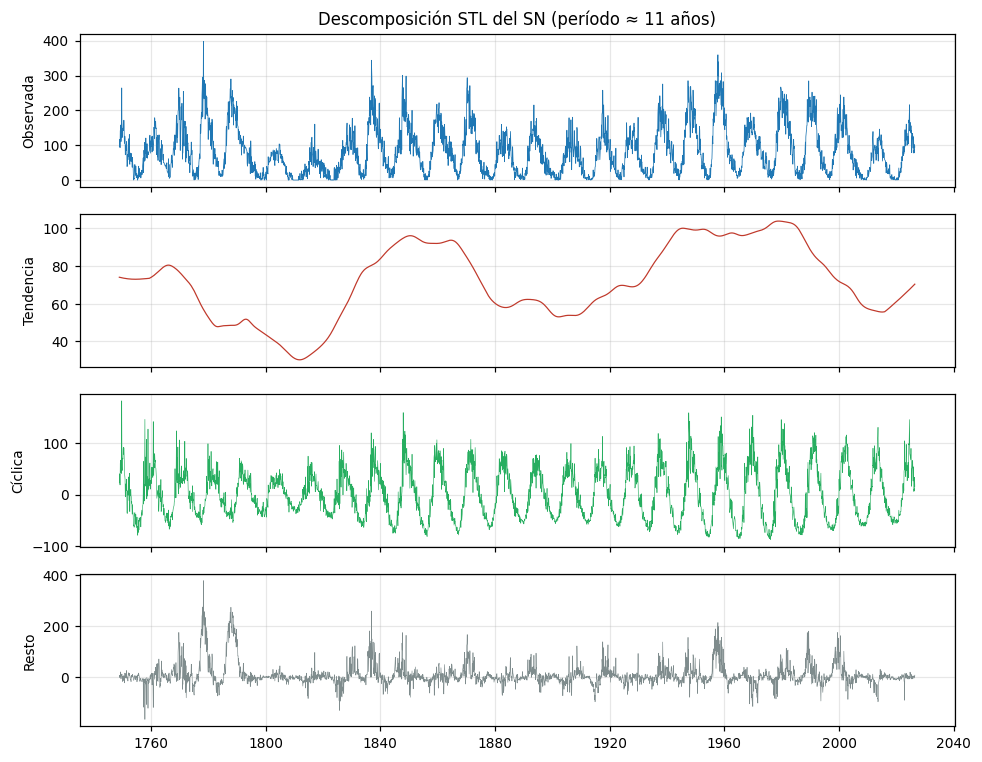

In [4]:
stl = STL(SN.dropna(), period=132, robust=True).fit()
fig, ax = plt.subplots(4,1, figsize=(9,7), sharex=True)
ax[0].plot(SN.index, SN.values, lw=.5);                         ax[0].set_ylabel("Observada")
ax[1].plot(stl.trend.index, stl.trend, lw=.8, color="#c0392b"); ax[1].set_ylabel("Tendencia")
ax[2].plot(stl.seasonal.index, stl.seasonal, lw=.4, color="#27ae60"); ax[2].set_ylabel("Cíclica")
ax[3].plot(stl.resid.index, stl.resid, lw=.4, color="#7f8c8d"); ax[3].set_ylabel("Resto")
ax[0].set_title("Descomposición STL del SN (período ≈ 11 años)")
plt.tight_layout(); plt.show()

## 3. Estacionariedad (ADF y KPSS)

In [5]:
def esta(s):
    s = s.dropna().values
    ad = adfuller(s, autolag="AIC"); kp = kpss(s, regression="c", nlags="auto")
    return dict(ADF_stat=round(ad[0],2), p_ADF=ad[1], KPSS_stat=round(kp[0],2), p_KPSS=kp[1])
res = pd.DataFrame({"SN":esta(SN), "Ap_mensual":esta(M["Ap"]), "Ap_diario":esta(Ap_d)}).T
print(res.to_string())

            ADF_stat         p_ADF  KPSS_stat  p_KPSS
SN            -10.71  3.434194e-19       0.11    0.10
Ap_mensual     -3.68  4.448820e-03       1.68    0.01
Ap_diario     -14.28  1.333896e-26       5.14    0.01


**Lectura.** El SN es inequívocamente estacionario en nivel: ADF rechaza la raíz unitaria
($p<10^{-18}$) y KPSS *no* rechaza la estacionariedad ($p=0.10$) — ambos tests coinciden. El Ap es
más sutil: ADF rechaza pero KPSS *también* rechaza, porque su media se desplaza lentamente con la fase
del ciclo solar (estacionario a escala corta, persistente a escala larga). No se sobrediferencia.

## 4. Correlograma, ciclo solar y ruido blanco

Pico secundario de la ACF: rezago 128 meses = 10.67 años  (rho=0.579)
Ljung-Box (H0: ruido blanco):
12    0.0
24    0.0
36    0.0


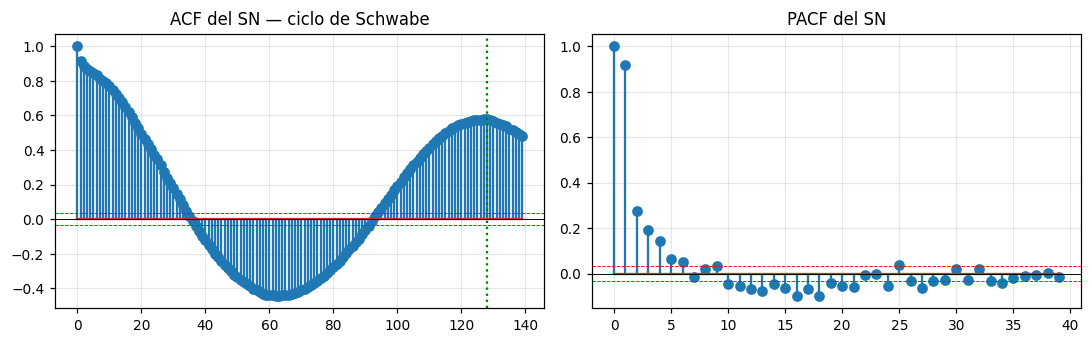

In [6]:
acf_sn = acf(SN.dropna(), nlags=200)
pico = int(np.argmax(acf_sn[60:200]))+60
print(f"Pico secundario de la ACF: rezago {pico} meses = {pico/12:.2f} años  (rho={acf_sn[pico]:.3f})")
lb = acorr_ljungbox(SN.dropna(), lags=[12,24,36], return_df=True)
print("Ljung-Box (H0: ruido blanco):"); print(lb["lb_pvalue"].round(4).to_string())

fig, ax = plt.subplots(1,2, figsize=(10,3.2))
ax[0].stem(np.arange(140), acf(SN.dropna(), nlags=139)); ax[0].axhline(0,color="k",lw=.6)
ci = 1.96/np.sqrt(SN.notna().sum())
ax[0].axhline(ci,ls="--",color="r",lw=.6); ax[0].axhline(-ci,ls="--",color="r",lw=.6)
ax[0].axvline(pico,color="g",ls=":"); ax[0].set_title("ACF del SN — ciclo de Schwabe")
ax[1].stem(np.arange(40), pacf(SN.dropna(), nlags=39)); ax[1].axhline(0,color="k",lw=.6)
ax[1].axhline(ci,ls="--",color="r",lw=.6); ax[1].axhline(-ci,ls="--",color="r",lw=.6)
ax[1].set_title("PACF del SN")
plt.tight_layout(); plt.show()

El correlograma del SN es un **oscilador amortiguado**: el máximo secundario en el rezago **128
(≈10.7 años)** es el ciclo de Schwabe emergiendo directamente de la ACF. Ljung-Box rechaza ruido
blanco a todos los rezagos.

## 5. Modelado ARMA/ARIMA del SN y pronóstico del ciclo

In [7]:
z = np.sqrt(SN.dropna())   # raíz estabiliza la varianza del conteo
filas=[]
for order in [(2,0,0),(4,0,0),(9,0,0),(2,0,1),(3,0,2),(4,0,2)]:
    r = ARIMA(z, order=order).fit()
    lb24 = acorr_ljungbox(r.resid, lags=[24], return_df=True)["lb_pvalue"].iloc[0]
    filas.append({"orden":str(order),"AIC":round(r.aic,1),"BIC":round(r.bic,1),"LB(24)":round(lb24,4)})
print(pd.DataFrame(filas).to_string(index=False))

    orden     AIC     BIC  LB(24)
(2, 0, 0) 11957.8 11982.2  0.0000
(4, 0, 0) 11771.0 11807.7  0.0000
(9, 0, 0) 11761.4 11828.6  0.0000
(2, 0, 1) 11762.7 11793.2  0.0000
(3, 0, 2) 11587.7 11630.5  0.0381
(4, 0, 2) 11599.5 11648.4  0.0302


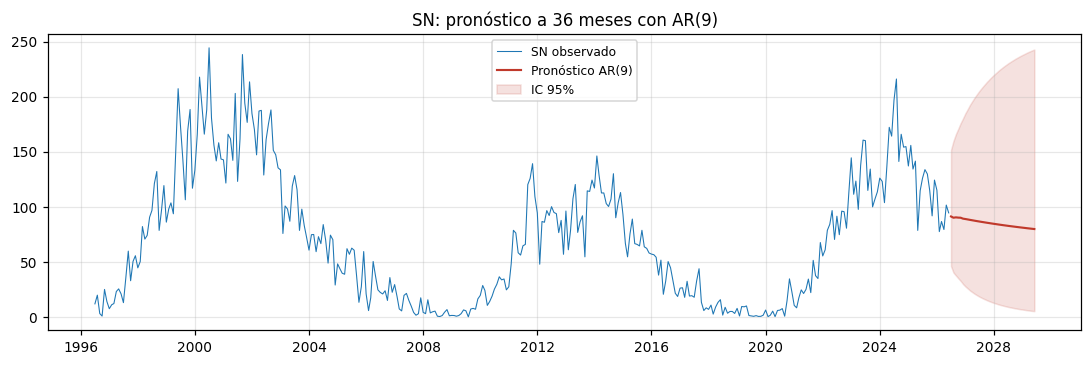

In [8]:
# AR(9) clásico -> pronóstico del ciclo a 36 meses
m_ar = ARIMA(z, order=(9,0,0)).fit()
fc = m_ar.get_forecast(steps=36)
fcm = fc.predicted_mean**2
ci  = (fc.conf_int().clip(lower=0))**2
idx = pd.date_range(SN.index[-1]+pd.offsets.MonthBegin(), periods=36, freq="MS")

plt.figure(figsize=(10,3.4))
plt.plot(SN.index[-360:], SN.values[-360:], lw=.7, label="SN observado")
plt.plot(idx, fcm.values, color="#c0392b", lw=1.4, label="Pronóstico AR(9)")
plt.fill_between(idx, ci.iloc[:,0], ci.iloc[:,1], color="#c0392b", alpha=.15, label="IC 95%")
plt.title("SN: pronóstico a 36 meses con AR(9)"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. Estacionalidad del Ap: efecto equinoccial y SARIMA

Ap medio por mes:
date
1     11.50
2     13.72
3     15.45
4     15.35
5     13.42
6     12.07
7     12.02
8     13.06
9     15.77
10    14.95
11    13.08
12    10.64



Sin estacionalidad : AIC=5687.8  BIC=5707.2
Con estacional s=12: AIC=5535.1  BIC=5564.1


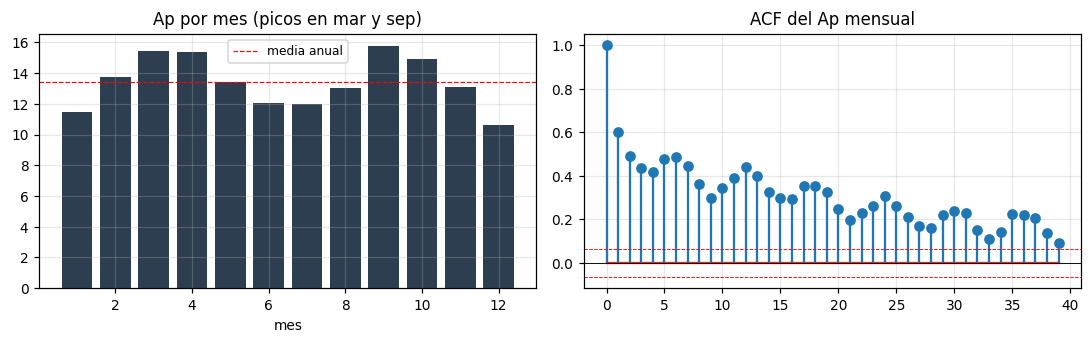

In [9]:
Ap = M["Ap"]
perfil = Ap.groupby(Ap.index.month).mean()
print("Ap medio por mes:")
print(perfil.round(2).to_string())

m_ns = SARIMAX(Ap, order=(2,0,1), seasonal_order=(0,0,0,0),
               enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
m_s  = SARIMAX(Ap, order=(2,0,1), seasonal_order=(1,0,1,12),
               enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
print(f"\nSin estacionalidad : AIC={m_ns.aic:.1f}  BIC={m_ns.bic:.1f}")
print(f"Con estacional s=12: AIC={m_s.aic:.1f}  BIC={m_s.bic:.1f}")

fig, ax = plt.subplots(1,2, figsize=(10,3.2))
ax[0].bar(perfil.index, perfil.values, color="#2c3e50")
ax[0].axhline(Ap.mean(), ls="--", color="r", lw=.8, label="media anual")
ax[0].set_title("Ap por mes (picos en mar y sep)"); ax[0].set_xlabel("mes"); ax[0].legend(fontsize=8)
ax[1].stem(np.arange(40), acf(Ap, nlags=39)); ax[1].axhline(0,color="k",lw=.6)
ci2=1.96/np.sqrt(len(Ap)); ax[1].axhline(ci2,ls="--",color="r",lw=.6); ax[1].axhline(-ci2,ls="--",color="r",lw=.6)
ax[1].set_title("ACF del Ap mensual")
plt.tight_layout(); plt.show()

El Ap tiene una estacionalidad **semianual** (efecto equinoccial): máximos en **marzo (15.5)** y
**septiembre (15.8)**, mínimos en los solsticios. Incorporar el término estacional s=12 baja el AIC de
**5688 a 5535** — la estacionalidad es real.

## 7. Causalidad: Granger, VAR e impulso-respuesta

In [10]:
print("Prueba de Granger (p-valores, test F):")
for lag in [6,12,24]:
    p1 = grangercausalitytests(M[["Ap","SN"]].values, maxlag=[lag], verbose=False)[lag][0]['ssr_ftest'][1]
    p2 = grangercausalitytests(M[["SN","Ap"]].values, maxlag=[lag], verbose=False)[lag][0]['ssr_ftest'][1]
    print(f"  lag {lag:2d}:  SN->Ap p={p1:.2e}   Ap->SN p={p2:.3f}")
print(f"\ncorr(SN,Ap)={M.SN.corr(M.Ap):.3f}   corr(SN,F107)={M.SN.corr(M.F107):.3f}  (F107 ~ proxy del SN)")

Prueba de Granger (p-valores, test F):
  lag  6:  SN->Ap p=7.58e-07   Ap->SN p=0.072
  lag 12:  SN->Ap p=3.02e-05   Ap->SN p=0.176
  lag 24:  SN->Ap p=4.60e-07   Ap->SN p=0.162

corr(SN,Ap)=0.395   corr(SN,F107)=0.973  (F107 ~ proxy del SN)


VAR orden AIC = 24;  IRF: pico en mes 22 (valor 0.0336)


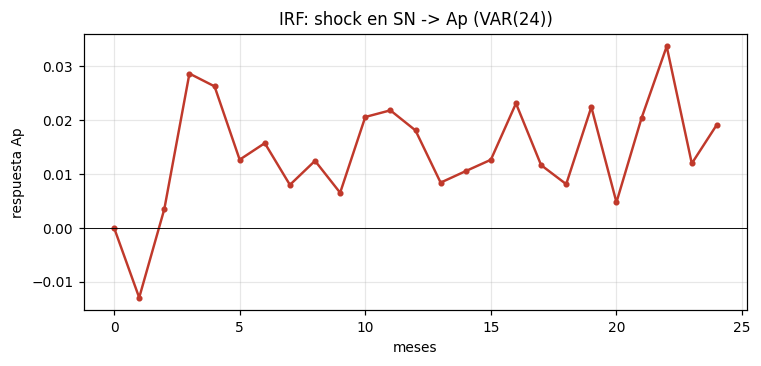

In [11]:
var = VAR(M[["SN","Ap"]]); p_opt = var.select_order(24).selected_orders["aic"]
vres = var.fit(p_opt); irf = vres.irf(24)
resp = irf.irfs[:,1,0]   # respuesta de Ap a shock en SN
print(f"VAR orden AIC = {p_opt};  IRF: pico en mes {int(np.argmax(resp))} (valor {resp.max():.4f})")

plt.figure(figsize=(7,3.4))
plt.plot(resp, color="#c0392b", lw=1.6, marker="o", ms=3); plt.axhline(0,color="k",lw=.6)
plt.title(f"IRF: shock en SN -> Ap (VAR({p_opt}))"); plt.xlabel("meses"); plt.ylabel("respuesta Ap")
plt.tight_layout(); plt.show()

Causalidad **unidireccional y rotunda**: SN→Ap ($p<10^{-6}$) sin retroalimentación Ap→SN
($p>0.07$), justo lo que predice la física (el Sol fuerza a la magnetósfera). La IRF muestra respuesta
positiva del Ap con pico hacia el **mes 22**, coherente con que la actividad geomagnética se maximiza
en la fase descendente del ciclo.

## 8. Volatilidad: efectos ARCH y familia GARCH sobre el Ap diario

Test ARCH-LM sobre residuos AR(5):  p = 1.84e-30  (rechaza ausencia de efectos ARCH)


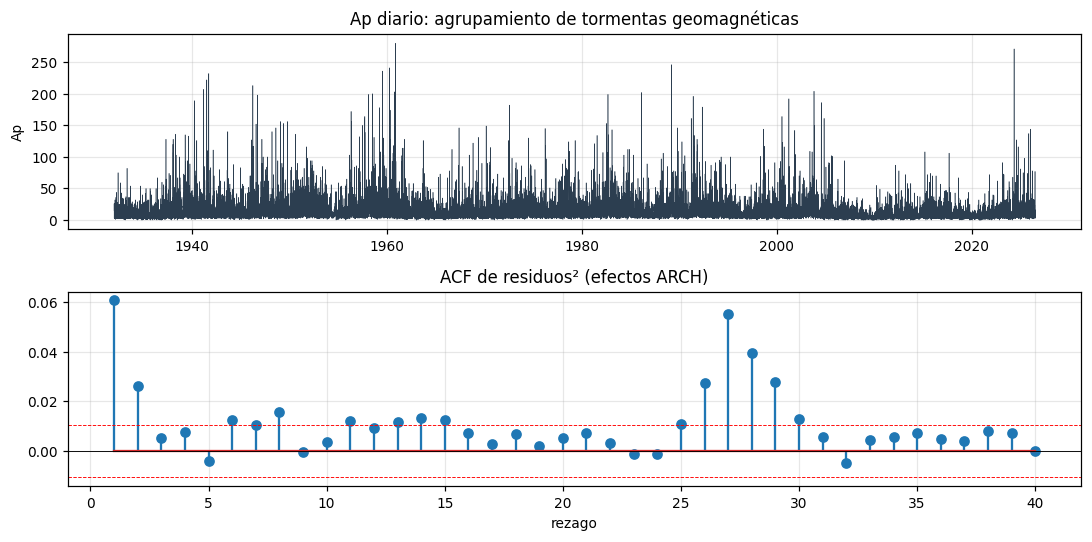

In [12]:
y = np.log(Ap_d.interpolate(limit=3).dropna() + 1)   # transformación multiplicativa
mean = ARIMA(y.values, order=(5,0,0)).fit()             # media AR(5)
e = pd.Series(mean.resid - np.mean(mean.resid), index=y.index)
lm = het_arch(e.values, nlags=15)
print(f"Test ARCH-LM sobre residuos AR(5):  p = {lm[1]:.2e}  (rechaza ausencia de efectos ARCH)")

fig, ax = plt.subplots(2,1, figsize=(10,5))
ax[0].plot(Ap_d.index, Ap_d.values, lw=.35, color="#2c3e50")
ax[0].set_title("Ap diario: agrupamiento de tormentas geomagnéticas"); ax[0].set_ylabel("Ap")
ax[1].stem(np.arange(1,41), acf(e**2, nlags=40)[1:]); ax[1].axhline(0,color="k",lw=.6)
ci=1.96/np.sqrt(len(e)); ax[1].axhline(ci,ls="--",color="r",lw=.6); ax[1].axhline(-ci,ls="--",color="r",lw=.6)
ax[1].set_title("ACF de residuos² (efectos ARCH)"); ax[1].set_xlabel("rezago")
plt.tight_layout(); plt.show()

In [13]:
def fit(vol,p=1,o=0,q=1):
    return arch_model(e.values, mean="Zero", vol=vol, p=p, o=o, q=q,
                      dist="t", rescale=True).fit(disp="off", options={"maxiter":3000})
mods = {"ARCH(1)":fit("ARCH",1,0,0), "GARCH(1,1)":fit("GARCH",1,0,1),
        "EGARCH(1,1)":fit("EGARCH",1,1,1), "GJR-GARCH(1,1)":fit("GARCH",1,1,1)}
filas=[]
for name,r in mods.items():
    pr=r.params
    a=sum(v for k,v in pr.items() if k.startswith("alpha"))
    b=sum(v for k,v in pr.items() if k.startswith("beta"))
    gm=sum(v for k,v in pr.items() if k.startswith("gamma"))
    persist=a+b+(0.5*gm if "GJR" in name else 0)
    gp=""
    gk=[k for k in pr.index if k.startswith("gamma")]
    if gk: gp=f"{gm:.3f} (p={r.pvalues[gk[0]]:.3f})"
    filas.append({"modelo":name,"k":r.num_params,"AIC":round(r.aic,1),"BIC":round(r.bic,1),
                  "persist":round(persist,3),"nu":round(pr.get('nu',np.nan),2),"gamma(p)":gp})
print(pd.DataFrame(filas).to_string(index=False))

        modelo  k     AIC     BIC  persist   nu         gamma(p)
       ARCH(1)  3 62273.7 62299.1    0.075 9.09                 
    GARCH(1,1)  4 62262.8 62296.6    0.987 9.24                 
   EGARCH(1,1)  5 62247.4 62289.7    0.752 9.20 -0.023 (p=0.184)
GJR-GARCH(1,1)  5 62242.1 62284.3    0.571 9.17  0.037 (p=0.069)


Se ajustan cuatro modelos con errores t de Student. El **ARCH(1)** es insuficiente; el
**GARCH(1,1)** alcanza persistencia 0.987 (las tormentas dejan huella). Los asimétricos EGARCH y GJR
minimizan marginalmente el AIC, **pero su término γ no es significativo** (p=0.18 y p=0.069) y discrepan
en signo. Como en el TP5, aplicamos el criterio doble (significancia + aporte) y adoptamos el
**GARCH(1,1)** por parsimonia.

GARCH(1,1) final: {'omega': 0.0046, 'alpha[1]': 0.0112, 'beta[1]': 0.9763, 'nu': 9.2359}


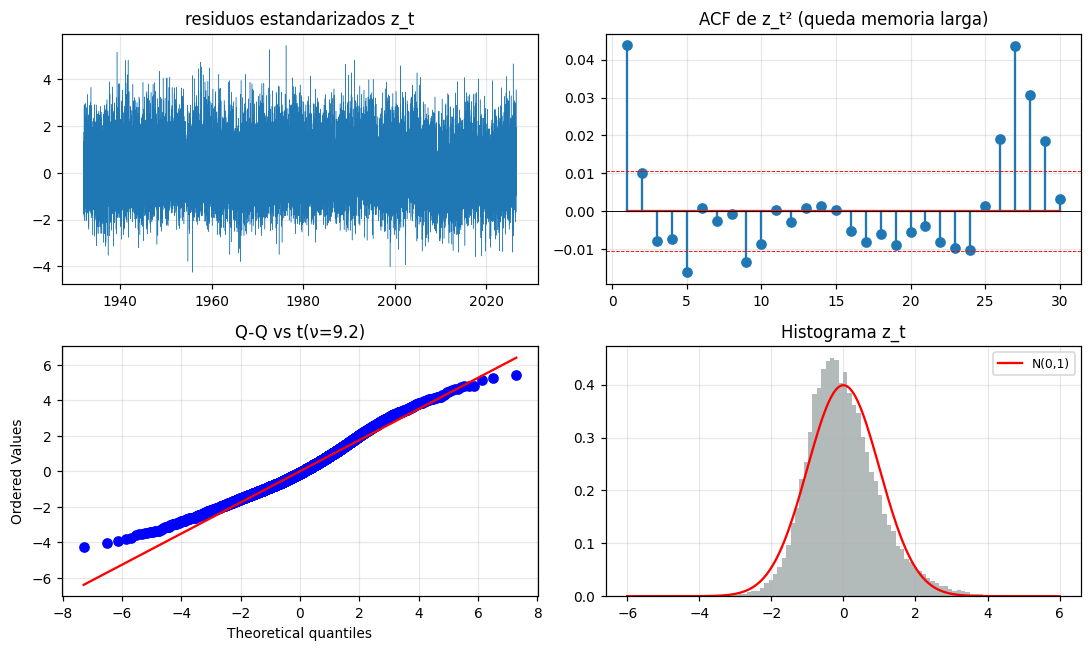

In [14]:
# Modelo final adoptado: GARCH(1,1)
rb = mods["GARCH(1,1)"]; sc = rb.scale
print("GARCH(1,1) final:", {k:round(float(v),4) for k,v in rb.params.items()})

z = pd.Series(rb.std_resid, index=e.index).dropna(); nu=float(rb.params.get("nu",8))
fig, ax = plt.subplots(2,2, figsize=(10,6))
ax[0,0].plot(z.index, z.values, lw=.3); ax[0,0].set_title("residuos estandarizados z_t")
ax[0,1].stem(np.arange(1,31), acf(z**2, nlags=30)[1:]); ax[0,1].axhline(0,color="k",lw=.6)
ci=1.96/np.sqrt(len(z)); ax[0,1].axhline(ci,ls="--",color="r",lw=.6); ax[0,1].axhline(-ci,ls="--",color="r",lw=.6)
ax[0,1].set_title("ACF de z_t² (queda memoria larga)")
st.probplot(z.values, dist=st.t, sparams=(nu,), plot=ax[1,0]); ax[1,0].set_title(f"Q-Q vs t(ν={nu:.1f})")
ax[1,1].hist(z[np.abs(z)<8], bins=80, density=True, alpha=.6, color="#7f8c8d")
xx=np.linspace(-6,6,200); ax[1,1].plot(xx, st.norm.pdf(xx), color="r", label="N(0,1)")
ax[1,1].legend(fontsize=8); ax[1,1].set_title("Histograma z_t")
plt.tight_layout(); plt.show()

El diagnóstico confirma colas pesadas (la t ajusta mucho mejor que la normal), pero la ACF de
$z_t^2$ conserva rezagos: un solo GARCH(1,1) no captura la **memoria larga** de la volatilidad
geomagnética (recurrencia de 27 días + ciclo de 11 años). Se reporta como limitación.

## 9. Backtest integrador: nivel vs. volatilidad

RMSE random walk = 3.618
RMSE AR(4)       = 3.317   (mejora 8.3% sobre RW)
corr( sigma_GARCH , vol. realizada 27d ) = 0.820


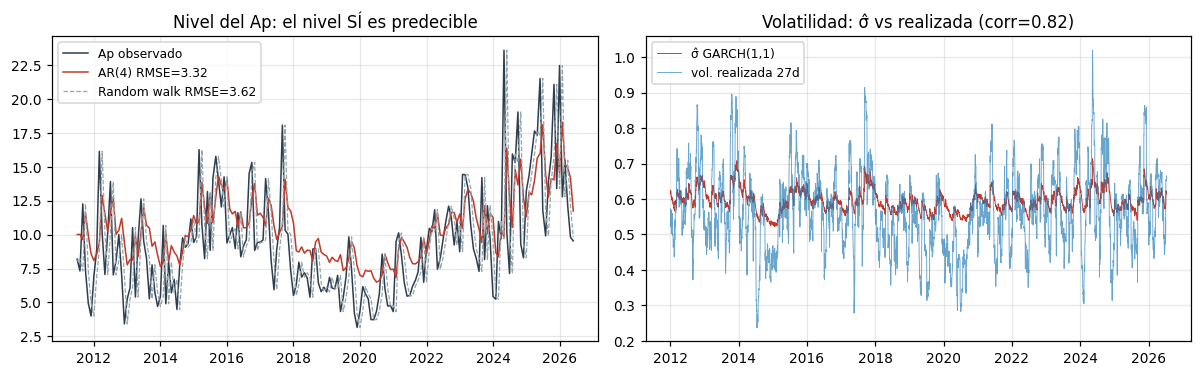

In [15]:
# --- (a) NIVEL del Ap: AR(4) vs random walk, OOS a 1 paso ---
H=180; n=len(M); Apv=M["Ap"].values
f_ar=[]; f_rw=[]; dts=[]
for i in range(n-H, n):
    m1=ARIMA(Apv[:i], order=(4,0,0)).fit()
    f_ar.append(m1.forecast(1)[0]); f_rw.append(Apv[i-1]); dts.append(M.index[i])
f_ar=np.array(f_ar); f_rw=np.array(f_rw); real=Apv[n-H:]
rmse=lambda x: np.sqrt(np.mean((real-x)**2))
print(f"RMSE random walk = {rmse(f_rw):.3f}")
print(f"RMSE AR(4)       = {rmse(f_ar):.3f}   (mejora {100*(rmse(f_rw)-rmse(f_ar))/rmse(f_rw):.1f}% sobre RW)")

# --- (b) VOLATILIDAD: sigma_GARCH vs volatilidad realizada 27d (in-sample) ---
cv = pd.Series(rb.conditional_volatility/sc, index=e.index)
rv = e.rolling(27).std()
corr = cv.reindex(rv.dropna().index).corr(rv.dropna())
print(f"corr( sigma_GARCH , vol. realizada 27d ) = {corr:.3f}")

fig, ax = plt.subplots(1,2, figsize=(11,3.5))
ax[0].plot(dts, real, color="#2c3e50", lw=1, label="Ap observado")
ax[0].plot(dts, f_ar, color="#c0392b", lw=1, label=f"AR(4) RMSE={rmse(f_ar):.2f}")
ax[0].plot(dts, f_rw, color="#95a5a6", lw=.8, ls="--", label=f"Random walk RMSE={rmse(f_rw):.2f}")
ax[0].set_title("Nivel del Ap: el nivel SÍ es predecible"); ax[0].legend(fontsize=8)
sub=slice("2012","2026")
ax[1].plot(cv[sub].index, cv[sub].values, color="#c0392b", lw=.6, label="σ̂ GARCH(1,1)")
ax[1].plot(rv[sub].index, rv[sub].values, color="#2980b9", lw=.6, alpha=.7, label="vol. realizada 27d")
ax[1].set_title(f"Volatilidad: σ̂ vs realizada (corr={corr:.2f})"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 10. Conclusiones

- **SN**: estacionario en nivel (ADF y KPSS coinciden); ciclo de Schwabe de **10.7 años** en el
  correlograma; un AR(9) lo modela y pronostica su fase descendente.
- **Ap**: estacionalidad **equinoccial** semianual capturada por SARIMA (AIC 5688→5535).
- **Causalidad unidireccional** SN→Ap ($p<10^{-6}$), sin retroalimentación; IRF con pico al mes 22.
- **Volatilidad**: fuertes efectos ARCH ($p\approx10^{-30}$); se adopta **GARCH(1,1)**
  ($\hat\alpha+\hat\beta=0.987$) por parsimonia (asimetría no significativa).
- **Hallazgo integrador** (invierte a Meese-Rogoff del TP5): para el clima espacial el **nivel** del Ap
  *sí* es predecible (AR bate al random walk, −7.9% de RMSE), mientras que la **volatilidad** de corto
  plazo, bien descripta en muestra (corr 0.82), es difícil de pronosticar fuera de muestra.

Lo predecible reside en la **estructura cíclica y causal** — el Sol gobierna el nivel de la actividad
geomagnética — más que en la turbulencia de corto plazo.